In [ ]:
# Setup cell
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import os
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

In [9]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. Data Reading and  Pre-processing

In [11]:
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv')

# Print first five rows of datatset
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/mpi_roof_2025.csv'

In [ ]:
# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

df.head()

,T (degC)
Date Time,
2025-01-01 00:10:00,-1.56
2025-01-01 00:20:00,-0.90
2025-01-01 00:30:00,-0.51
2025-01-01 00:40:00,-0.27
2025-01-01 00:50:00,-0.09


In [ ]:
# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-04"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

print(f"Short-term shape: {df_short.shape}")
print(f"Long-term shape:  {df_long.shape}")

Short-term shape: (575, 1)
Long-term shape:  (21743, 1)


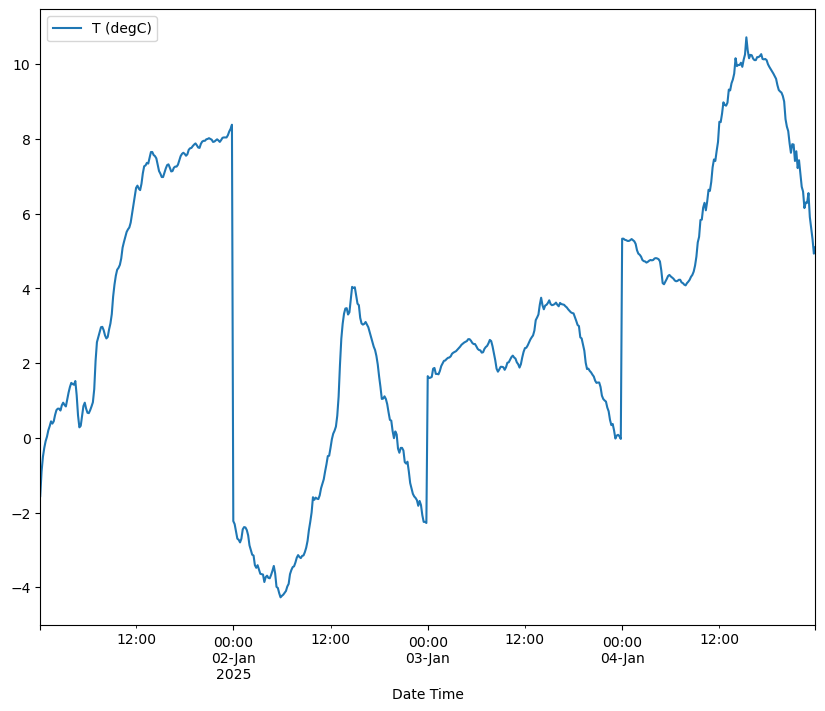

In [ ]:
df_short.plot()
plt.show()

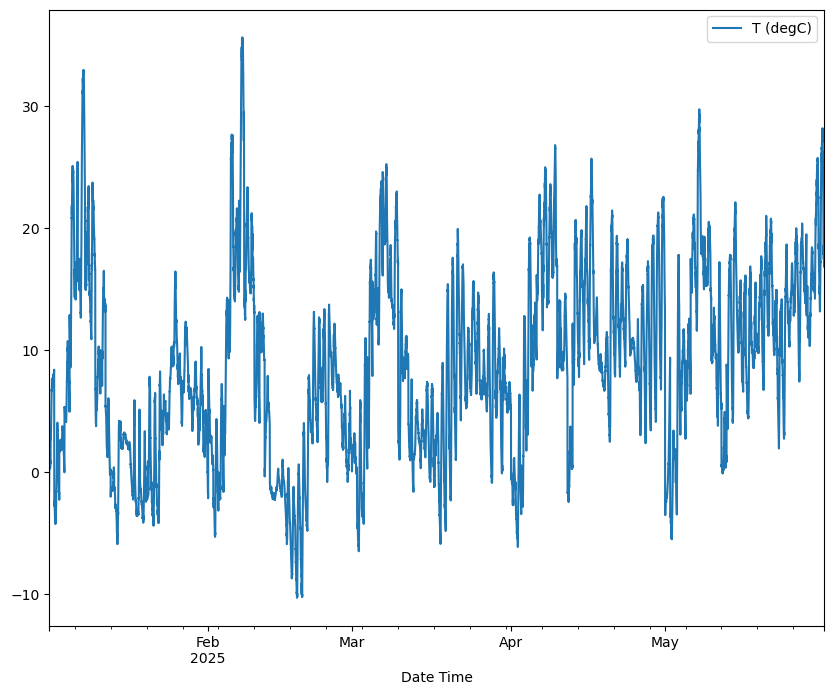

In [ ]:
df_long.plot()
plt.show()

c:\Users\jaspe\anaconda3\Lib\site-packages\statsmodels\base\optimizer.py:21: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method lbfgs is: m, pgtol, factr, maxfun, epsilon, approx_grad, bounds, loglike_and_score, iprint. The list of unsupported keyword arguments passed include: optimized. After release 0.14, this will raise.
  warnings.warn(
c:\Users\jaspe\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


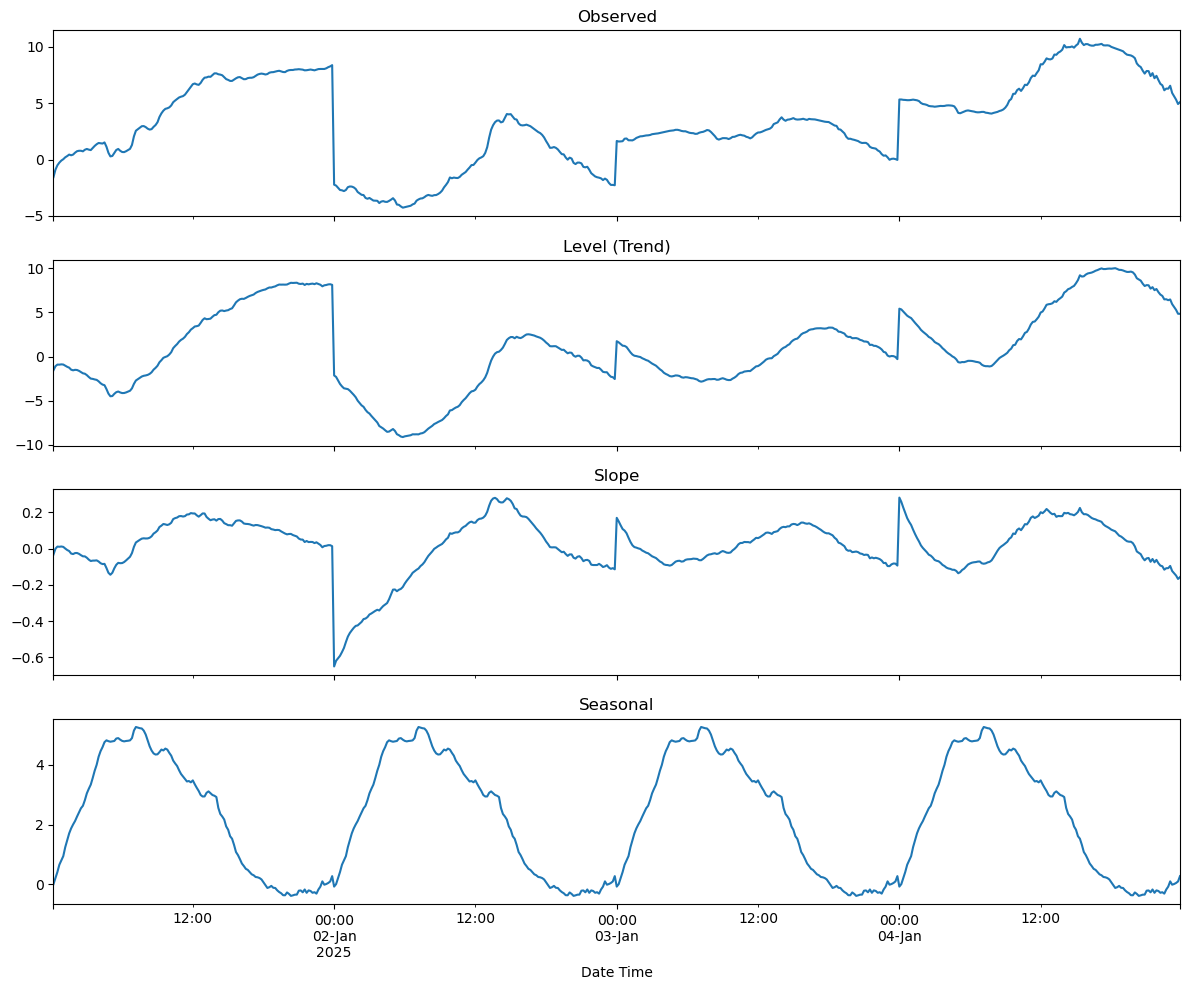

In [ ]:
# ETS Decomposition for short forecasting
model_short = ETSModel(
    df_short["T (degC)"],
    error="add",        # Additive error
    trend="add",        # Additive trend
    seasonal="add",     # Additive seasonality
    damped_trend=False,
    seasonal_periods=144  # 144 × 10min = 1 full day
)
fit_short = model_short.fit(optimized=True)

# ETS plot
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

df_short["T (degC)"].plot(ax=axes[0], title="Observed")
fit_short.level.plot(ax=axes[1], title="Level (Trend)")
fit_short.slope.plot(ax=axes[2], title="Slope")
fit_short.season.plot(ax=axes[3], title="Seasonal")

plt.tight_layout()
plt.show()

In [ ]:
# ETS Decomposition for long forecasting
model_long = ETSModel(
    df_long["T (degC)"],
    error="add",
    trend="add",
    seasonal="add",
    damped_trend=False,
    seasonal_periods=144  # Daily seasonality (144 × 10min = 1 day)
)

fit_long = model_long.fit(optimized=True)

# ETS plot
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

df_long["T (degC)"].plot(ax=axes[0], title="Observed")
fit_long.level.plot(ax=axes[1], title="Level (Trend)")
fit_long.slope.plot(ax=axes[2], title="Slope")
fit_long.season.plot(ax=axes[3], title="Seasonal")

plt.tight_layout()
plt.show()

c:\Users\jaspe\anaconda3\Lib\site-packages\statsmodels\base\optimizer.py:21: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method lbfgs is: m, pgtol, factr, maxfun, epsilon, approx_grad, bounds, loglike_and_score, iprint. The list of unsupported keyword arguments passed include: optimized. After release 0.14, this will raise.
  warnings.warn(
c:\Users\jaspe\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


KeyboardInterrupt: 

DatetimeIndex(['2025-01-01 00:10:00', '2025-01-01 00:20:00',
               '2025-01-01 00:30:00', '2025-01-01 00:40:00',
               '2025-01-01 00:50:00', '2025-01-01 01:00:00',
               '2025-01-01 01:10:00', '2025-01-01 01:20:00',
               '2025-01-01 01:30:00', '2025-01-01 01:40:00',
               ...
               '2025-12-31 22:30:00', '2025-12-31 22:40:00',
               '2025-12-31 22:50:00', '2025-12-31 23:00:00',
               '2025-12-31 23:10:00', '2025-12-31 23:20:00',
               '2025-12-31 23:30:00', '2025-12-31 23:40:00',
               '2025-12-31 23:50:00', '2026-01-01 00:00:00'],
              dtype='datetime64[ns]', name='Date Time', length=52560, freq='10min')